# Étape 2 : Résolution du problème (P) en coordonnées polaires par la MEF

## Problème aux limites

$$(P)\ \begin{cases} \text{Trouver } T(r) \text{ tel que :} \\ -\lambda\,\Delta T = s \quad \text{dans } \Omega = ]R_0,R_1[ \\ T(R_0) = 0 \quad \text{(Dirichlet)} \\ \dfrac{dT}{dr}(R_1) = -H\,T(R_1) \quad \text{(Robin)} \end{cases}$$

avec $\Delta T = \dfrac{d^2T}{dr^2} + \dfrac{1}{r}\dfrac{dT}{dr}$.

## Formulation variationnelle

Par symétrie axiale ($\iint_\Omega f\,d\Omega = 2\pi\int_{R_0}^{R_1}f\cdot r\,dr$) :

$$(PV)\ \begin{cases}
\text{Trouver } T\in V_{R_0} \text{ tel que } a(T,\Theta)=L(\Theta),\ \forall\Theta\in V_{R_0}\\
a(T,\Theta) = 2\pi\lambda\displaystyle\int_{R_0}^{R_1}T'\Theta'\,r\,dr + 2\pi R_1\lambda H\,T(R_1)\Theta(R_1)\\
L(\Theta) = 2\pi s\displaystyle\int_{R_0}^{R_1}\Theta\,r\,dr
\end{cases}$$

**Remarque :** Avec les fonctions de base P2 choisies (mêmes que l'étape 1), toutes les $\tau_i$ s'annulent en $R_0$ — la condition de Dirichlet $T(R_0)=0$ est donc satisfaite **automatiquement**, sans modification du système. La condition de Robin en $R_1$ est traitée **naturellement** via le terme de bord dans $a$.

In [40]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt


r_sym = sp.symbols('r')

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# ── Paramètres physiques et numériques ──
R0  = 2.0    # Rayon intérieur
R1  = 5.0    # Rayon extérieur
lam = 1.0    # Conductivité thermique λ
H   = 8.33    # Coefficient d'échange (condition de Robin)
s   = 3.0    # Terme source volumique
K   = 4      # Nombre d'éléments (maillage régulier de k+1 segments)

# Même formule que l'étape 1 : h = L/(2*(K+1)) avec L = R1-R0
h   = (R1 - R0) / (2 * (K + 1))
dim = 2 * K + 1   # nombre de DDL (noeuds intérieurs + bord R1)

r_range = np.linspace(R0, R1, 500)

In [ ]:
def tau_i(i, r_val, h, R0):
    if i % 2 != 0:  # ── nœud milieu (impair) ──
        left  = R0 + (i - 1) * h
        right = R0 + (i + 1) * h
        return sp.Piecewise(
            (-(r_val - left) * (r_val - right) / (h**2),
             (r_val >= left) & (r_val <= right)),
            (0.0, True)
        )
    else:           # ── nœud extrémité (pair) ──
        left_ext  = R0 + (i - 2) * h   # r_{i-2}
        mid_left  = R0 + (i - 1) * h   # r_{i-1} (milieu gauche)
        ri        = R0 + i * h          # r_i (le nœud lui-même)
        mid_right = R0 + (i + 1) * h   # r_{i+1} (milieu droit)
        right_ext = R0 + (i + 2) * h   # r_{i+2}

        # Base de Lagrange P2 sur l'élément gauche [r_{i-2}, r_i]
       
        left_piece  = ((r_val - left_ext) * (r_val - mid_left)) / (2 * h**2)

        # Base de Lagrange P2 sur l'élément droit [r_i, r_{i+2}]
        
        right_piece = ((r_val - mid_right) * (r_val - right_ext)) / (2 * h**2)

        return sp.Piecewise(
            (left_piece,  (r_val >= left_ext) & (r_val <= ri)),
            (right_piece, (r_val > ri)        & (r_val <= right_ext)),
            (0.0, True)
        )

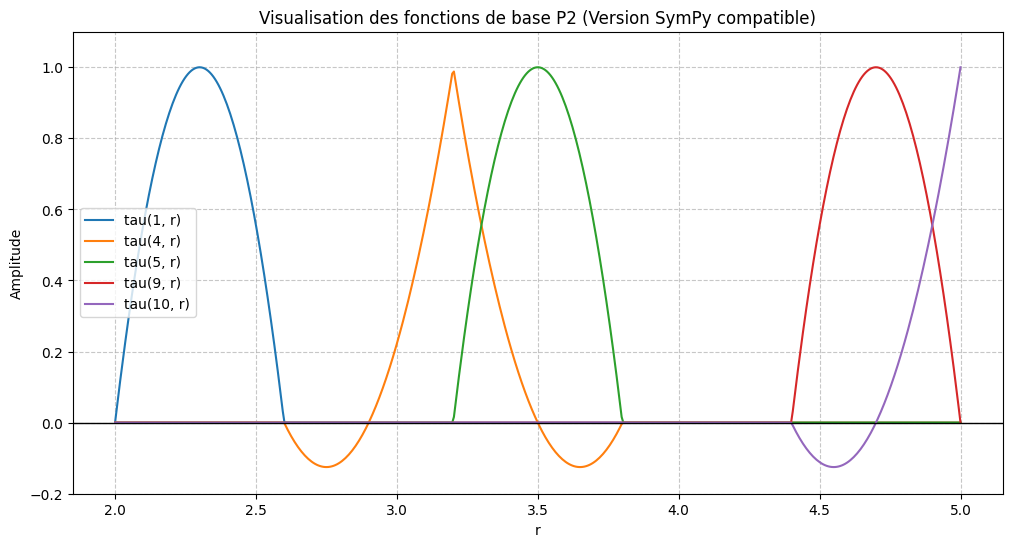

In [ ]:

indices_a_tracer = [1, K, K+1, 2*K+1, 2*K+2]
plt.figure(figsize=(12, 6))

for i in indices_a_tracer:
    if i <= dim + 1:
        tau_num = sp.lambdify(r_sym, tau_i(i, r_sym, h, R0), 'numpy')
        y_vals  = tau_num(r_range)
        plt.plot(r_range, y_vals, label=f'tau({i}, r)')

plt.title("Visualisation des fonctions de base P2 (Version SymPy compatible)")
plt.xlabel("r")
plt.ylabel("Amplitude")
plt.axhline(0, color='black', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.ylim(-0.2, 1.1)
plt.show()

In [ ]:
def source(r):
    return s

ML = np.zeros(dim + 1)
for i in range(1, dim + 2):
    val, _ = quad(
        lambda r: 2 * np.pi * float(tau_i(i, r, h, R0)) * source(r) * r,
        R0, R1
    )
    ML[i - 1] = val

print("Vecteur ML :", ML)

Vecteur ML : [17.34159145  9.80176908 21.86548487 12.06371579 26.38937829 14.3256625
 30.91327171 16.58760921 35.43716513  9.42477796]


In [ ]:
def d_tau_i(i, r_val, h, R0):
    eps = 1e-6
    return (tau_i(i, r_val + eps, h, R0) - tau_i(i, r_val - eps, h, R0)) / (2 * eps)

#  Matrice de rigidité Rig 

Rig = np.zeros((dim + 1, dim + 1))
for i in range(1, dim + 2):
    for j in range(1, dim + 2):
        
        val, _ = quad(
            lambda r: lam * 2 * np.pi * d_tau_i(i, r, h, R0)
                                       * d_tau_i(j, r, h, R0) * r,
            R0, R1, limit=200
        )
        
        val += 2 * np.pi * R1 * lam * H \
             * float(tau_i(i, R1, h, R0)) \
             * float(tau_i(j, R1, h, R0))

        Rig[i - 1, j - 1] = val

print("Matrice de Rigidité :\n", Rig)

Matrice de Rigidité :
 [[ 128.45623298  -68.4169067     0.            0.            0.
     0.            0.            0.            0.            0.        ]
 [ -68.4169067   127.05996958  -76.79448711   10.12290966    0.
     0.            0.            0.            0.            0.        ]
 [   0.          -76.79448711  161.96655463  -85.17206752    0.
     0.            0.            0.            0.            0.        ]
 [   0.           10.12290966  -85.17206752  156.38150102  -93.54964793
    12.21730477    0.            0.            0.            0.        ]
 [   0.            0.            0.          -93.54964793  195.47687628
  -101.92722834    0.            0.            0.            0.        ]
 [   0.            0.            0.           12.21730477 -101.92722834
   185.70303246 -110.30480876   14.31169987    0.            0.        ]
 [   0.            0.            0.            0.            0.
  -110.30480876  228.98719793 -118.68238917    0.            0.    

In [ ]:

Msol = np.linalg.solve(Rig, ML)

def TempEF(r_val):
    res = 0
    for i in range(1, dim + 2):
        res += Msol[i - 1] * tau_i(i, r_val, h, R0)
    return res

In [ ]:

r_s = sp.Symbol('r', positive=True)
T   = sp.Function('T')


equation = sp.Eq(-lam * (T(r_s).diff(r_s, 2) + T(r_s).diff(r_s) / r_s), s)


sol_gen = sp.dsolve(equation, T(r_s))
T_gen   = sol_gen.rhs
C1, C2  = sp.symbols('C1 C2')
dT_gen  = sp.diff(T_gen, r_s)


sol_const   = sp.solve([
    sp.Eq(T_gen.subs(r_s, R0), 0),
    sp.Eq(dT_gen.subs(r_s, R1), -H * T_gen.subs(r_s, R1))
], [C1, C2])

Texact_expr = sp.simplify(T_gen.subs(sol_const))

print("La solution exacte trouvée par Python (Texact) est :")
display(Texact_expr)


Texact_sym = Texact_expr
f_exacte   = sp.lambdify(r_s, Texact_sym, 'numpy')

La solution exacte trouvée par Python (Texact) est :


-0.75*r**2 + 17.7074914382377*log(r) - 9.27389776520381

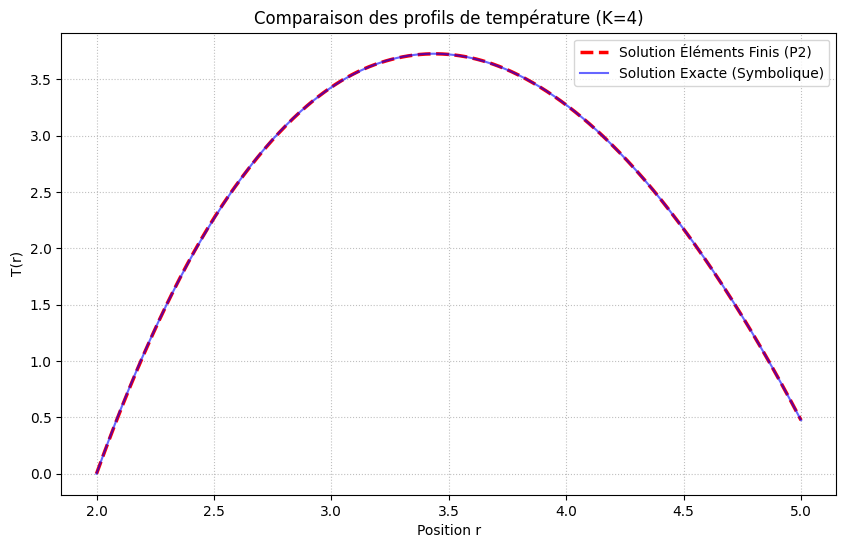

In [ ]:

TempEF_sym = sum(Msol[i - 1] * tau_i(i, r_sym, h, R0) for i in range(1, dim + 2))
f_EF_num   = sp.lambdify(r_sym, TempEF_sym, 'numpy')


y_EF    = f_EF_num(r_range)
y_exact = f_exacte(r_range)

# Graphique 
plt.figure(figsize=(10, 6))
plt.plot(r_range, y_EF,    'r--', label='Solution Éléments Finis (P2)', linewidth=2.5)
plt.plot(r_range, y_exact, 'b',   label='Solution Exacte (Symbolique)', alpha=0.6)

plt.title(f"Comparaison des profils de température (K={K})")
plt.xlabel("Position r")
plt.ylabel("T(r)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.8)
plt.show()

In [ ]:

f_num = sp.sympify(s)


dTexact_sym = sp.diff(Texact_sym, r_s)
a_exact = (2 * sp.pi * lam * sp.integrate(dTexact_sym**2 * r_s, (r_s, R0, R1))
           + 2 * sp.pi * R1 * lam * H * Texact_sym.subs(r_s, R1)**2)
L_exact = 2 * sp.pi * sp.integrate(f_num * Texact_sym * r_s, (r_s, R0, R1))
J_exact = sp.Rational(1, 2) * a_exact - L_exact


dTEF_sym = sp.diff(TempEF_sym, r_sym)
a_EF = (2 * sp.pi * lam * sp.integrate(dTEF_sym**2 * r_sym, (r_sym, R0, R1))
        + 2 * sp.pi * R1 * lam * H * TempEF_sym.subs(r_sym, R1)**2)
L_EF = 2 * sp.pi * sp.integrate(f_num * TempEF_sym * r_sym, (r_sym, R0, R1))
J_EF = sp.Rational(1, 2) * a_EF - L_EF


erreur_J = (J_EF - J_exact) / sp.Abs(J_exact)

# Affichage
print(f"{'Grandeur':<20} | {'Valeur':<15}")
print("-" * 45)
print(f"{'J(Exacte)':<20} | {J_exact.evalf():.10f}")
print(f"{'J(EF)':<20} | {J_EF.evalf():.10f}")
print(f"{'Erreur relative J':<20} | {erreur_J.evalf():.10f}")
print("-" * 45)

Grandeur             | Valeur         
---------------------------------------------
J(Exacte)            | -256.0080576971
J(EF)                | -255.9978349999
Erreur relative J    | 0.0000399312
---------------------------------------------


---
# Étape 2 — Partie B : Résolution avec des éléments **P1** (comparaison avec P2)

## Rappel : différence P1 / P2

| | P2 (partie A) | P1 (partie B) |
|---|---|---|
| Degré des polynômes | 2 | 1 |
| Noeuds par élément | 3 (extrémités + milieu) | 2 (extrémités seulement) |
| Noeuds totaux | $2K+2$ | $K+1$ |
| Pas nodal | $h = (R_1-R_0)/(2(K+1))$ | $h_{P1} = (R_1-R_0)/K$ |
| Convergence sur $J$ | $O(h^4)$ | $O(h^2)$ |

Les fonctions de base P1 sont des **chapeaux linéaires** : $\\tau_i$ vaut 1 en $r_i$, 0 aux noeuds voisins, et est **affine par morceaux** entre les noeuds.

In [ ]:

h_P1    = (R1 - R0) / K   
n_nodes = K + 1            


r_range_P1 = np.linspace(R0, R1, 500)

print(f'Maillage P1 : K={K} éléments, h_P1={h_P1:.4f}, {n_nodes} noeuds')
print(f'Noeuds : {[round(R0 + i*h_P1, 4) for i in range(n_nodes)]}')

Maillage P1 : K=4 éléments, h_P1=0.7500, 5 noeuds
Noeuds : [2.0, 2.75, 3.5, 4.25, 5.0]


In [ ]:
def tau_P1(i, r_val, h, R0, K):
    ri = R0 + i * h
    pieces = []
    if i > 0:       
        r_left = R0 + (i - 1) * h
        pieces.append(((r_val - r_left) / h,
                        (r_val >= r_left) & (r_val <= ri)))
    if i < K:       
        r_right = R0 + (i + 1) * h
        if i == 0:  
            pieces.append(((r_right - r_val) / h,
                            (r_val >= ri) & (r_val <= r_right)))
        else:
            pieces.append(((r_right - r_val) / h,
                            (r_val > ri) & (r_val <= r_right)))
    if not pieces:
        return sp.Integer(0)
    return sp.Piecewise(*pieces, (0.0, True))

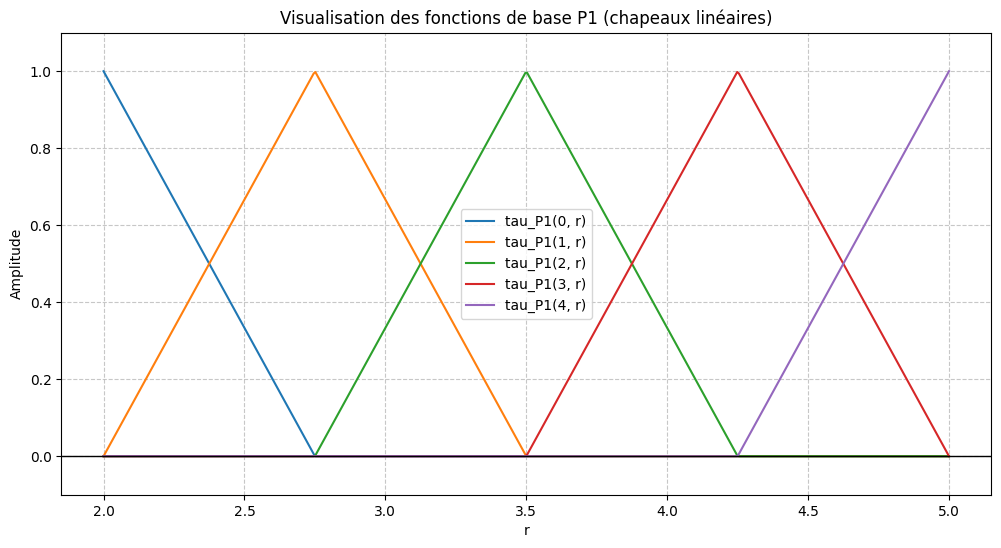

In [ ]:
# Visualisation des fonctions de base P1 
indices_P1 = [0, 1, K//2, K-1, K]
plt.figure(figsize=(12, 6))

for i in indices_P1:
    tau_num = sp.lambdify(r_sym, tau_P1(i, r_sym, h_P1, R0, K), 'numpy')
    y_vals  = tau_num(r_range_P1)
    plt.plot(r_range_P1, y_vals, label=f'tau_P1({i}, r)')

plt.title('Visualisation des fonctions de base P1 (chapeaux linéaires)')
plt.xlabel('r')
plt.ylabel('Amplitude')
plt.axhline(0, color='black', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.ylim(-0.1, 1.1)
plt.show()

In [ ]:

ML_P1 = np.zeros(n_nodes)
for i in range(n_nodes):
    val, _ = quad(
        lambda r: 2 * np.pi * float(tau_P1(i, r, h_P1, R0, K)) * source(r) * r,
        R0, R1
    )
    ML_P1[i] = val


ML_P1[0] = 0.0

print('Vecteur ML_P1 :', ML_P1)

Vecteur ML_P1 : [ 0.         38.87720909 49.48008429 60.0829595  33.57577149]


In [ ]:
def d_tau_P1(i, r_val, h, R0, K):
    """Dérivée numérique de tau_P1_i par différences finies centrées."""
    eps = 1e-7
    return (tau_P1(i, r_val+eps, h, R0, K) - tau_P1(i, r_val-eps, h, R0, K)) / (2*eps)

#  Matrice de rigidité Rig_P1 

Rig_P1 = np.zeros((n_nodes, n_nodes))
for i in range(n_nodes):
    for j in range(n_nodes):
        val, _ = quad(
            lambda r: lam * 2 * np.pi * d_tau_P1(i, r, h_P1, R0, K)
                                       * d_tau_P1(j, r, h_P1, R0, K) * r,
            R0, R1, limit=200
        )
        val += 2 * np.pi * R1 * lam * H \
             * float(tau_P1(i, R1, h_P1, R0, K)) \
             * float(tau_P1(j, R1, h_P1, R0, K))
        Rig_P1[i, j] = val


Rig_P1[0, :] = 0.0
Rig_P1[:, 0] = 0.0
Rig_P1[0, 0] = 1.0

print('Matrice de Rigidité P1 :\n', Rig_P1)

Matrice de Rigidité P1 :
 [[  1.           0.           0.           0.           0.        ]
 [  0.          46.07669211 -26.1799387    0.           0.        ]
 [  0.         -26.1799387   58.64306278 -32.46312408   0.        ]
 [  0.           0.         -32.46312408  71.20943369 -38.74630961]
 [  0.           0.           0.         -38.74630961 300.44097766]]


In [ ]:
#  Résolution 
Msol_P1 = np.linalg.solve(Rig_P1, ML_P1)

print('Températures nodales P1 :')
for i in range(n_nodes):
    r_node = R0 + i * h_P1
    print(f'  Noeud {i} (r = {r_node:.3f}) : T = {Msol_P1[i]:.6f}')

Températures nodales P1 :
  Noeud 0 (r = 2.000) : T = 0.000000
  Noeud 1 (r = 2.750) : T = 2.948030
  Noeud 2 (r = 3.500) : T = 3.703533
  Noeud 3 (r = 4.250) : T = 2.788616
  Noeud 4 (r = 5.000) : T = 0.471388


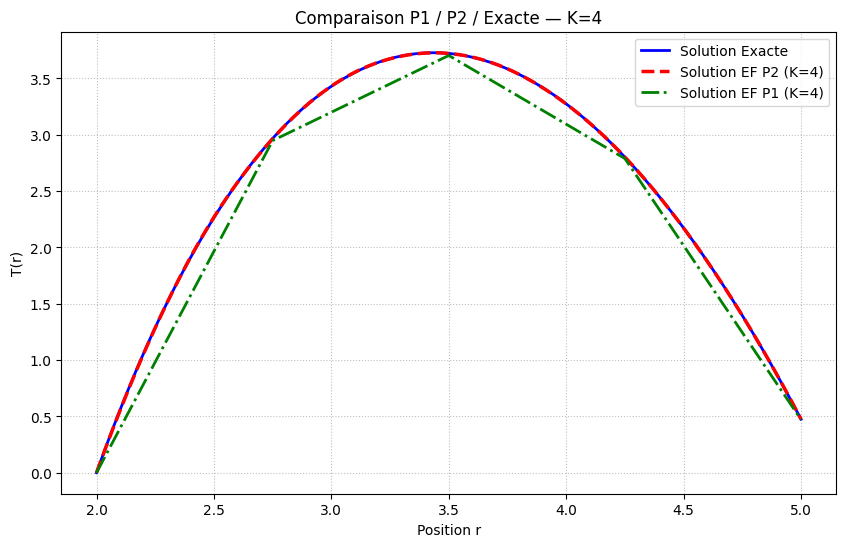

Erreur L∞  P1 = 3.387e-01
Erreur L∞  P2 = 5.705e-03
Rapport P1/P2 = 59.4x


In [ ]:

TempP1_sym = sum(Msol_P1[i] * tau_P1(i, r_sym, h_P1, R0, K) for i in range(n_nodes))
f_P1_num   = sp.lambdify(r_sym, TempP1_sym, 'numpy')

y_P1    = f_P1_num(r_range_P1)
y_P2    = f_EF_num(r_range_P1)    
y_exact = f_exacte(r_range_P1)

#  Graphique comparatif 
plt.figure(figsize=(10, 6))
plt.plot(r_range_P1, y_exact, 'b-',   linewidth=2,   label='Solution Exacte')
plt.plot(r_range_P1, y_P2,   'r--',   linewidth=2.5, label=f'Solution EF P2 (K={K})')
plt.plot(r_range_P1, y_P1,   'g-.',   linewidth=2,   label=f'Solution EF P1 (K={K})')

plt.title(f'Comparaison P1 / P2 / Exacte — K={K}')
plt.xlabel('Position r')
plt.ylabel('T(r)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.8)
plt.show()

err_P1 = np.max(np.abs(y_P1 - y_exact))
err_P2 = np.max(np.abs(y_P2 - y_exact))
print(f'Erreur L∞  P1 = {err_P1:.3e}')
print(f'Erreur L∞  P2 = {err_P2:.3e}')
print(f'Rapport P1/P2 = {err_P1/err_P2:.1f}x')

In [ ]:
#  Analyse d'erreur sur J pour P1 

dTP1_sym = sp.diff(TempP1_sym, r_sym)
a_P1 = (2 * sp.pi * lam * sp.integrate(dTP1_sym**2 * r_sym, (r_sym, R0, R1))
        + 2 * sp.pi * R1 * lam * H * TempP1_sym.subs(r_sym, R1)**2)
L_P1 = 2 * sp.pi * sp.integrate(sp.sympify(s) * TempP1_sym * r_sym, (r_sym, R0, R1))
J_P1 = sp.Rational(1, 2) * a_P1 - L_P1

erreur_J_P1 = (J_P1 - J_exact) / sp.Abs(J_exact)

print(f"{'Grandeur':<25} | {'Valeur':>15}")
print('-' * 45)
print(f"{'J(Exacte)':<25} | {J_exact.evalf():>15.10f}")
print(f"{'J(EF P2)':<25} | {J_EF.evalf():>15.10f}")
print(f"{'J(EF P1)':<25} | {J_P1.evalf():>15.10f}")
print(f"{'Erreur relative P2':<25} | {erreur_J.evalf():>15.10f}")
print(f"{'Erreur relative P1':<25} | {erreur_J_P1.evalf():>15.10f}")
print('-' * 45)

Grandeur                  |          Valeur
---------------------------------------------
J(Exacte)                 | -256.0080576971
J(EF P2)                  | -255.9978349999
J(EF P1)                  | -240.6189200064
Erreur relative P2        |    0.0000399312
Erreur relative P1        |    0.0601119271
---------------------------------------------


## Étude de convergence comparée P1 vs P2

On s'attend théoriquement à :
- **P1** : erreur sur $J$ en $O(h^2)$ — pente 2 sur le graphe log-log
- **P2** : erreur sur $J$ en $O(h^4)$ — pente 4 sur le graphe log-log

   K |     h_P1 |     Err J P1 |     h_P2 |     Err J P2
-------------------------------------------------------
   1 |   3.0000 |   9.0714e-01 |   0.7500 |   1.2523e-03
   2 |   1.5000 |   2.3647e-01 |   0.5000 |   2.8321e-04
   3 |   1.0000 |   1.0635e-01 |   0.3750 |   9.4778e-05
   4 |   0.7500 |   6.0112e-02 |   0.3000 |   3.9931e-05


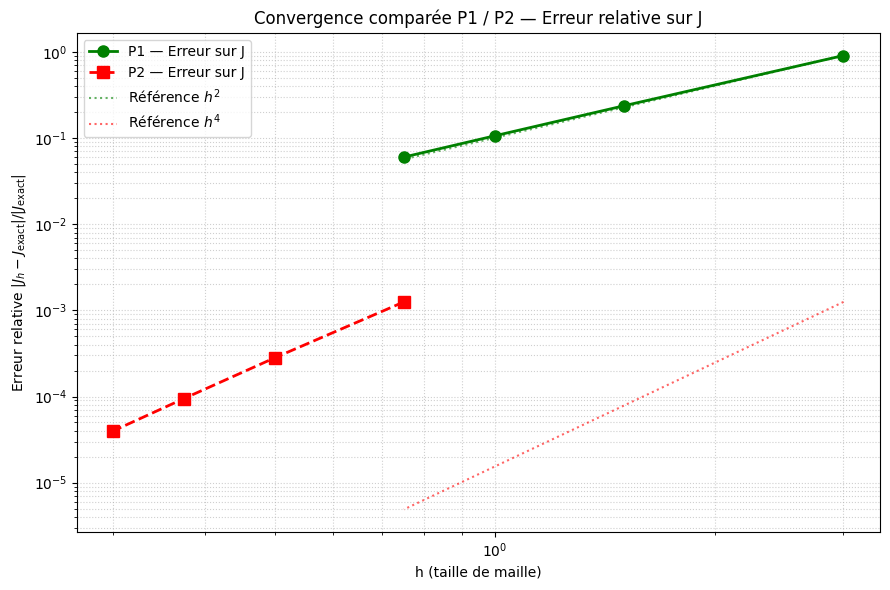

In [ ]:
def resoudre_P1_conv(K_val):
    """Résout (P) avec P1 pour K_val éléments."""
    h_loc = (R1 - R0) / K_val
    n_loc = K_val + 1

    ML_loc = np.zeros(n_loc)
    for i in range(n_loc):
        v, _ = quad(
            lambda r, _i=i, _h=h_loc:
                2*np.pi*s * float(tau_P1(_i, r, _h, R0, K_val)) * r,
            R0, R1, limit=200)
        ML_loc[i] = v
    ML_loc[0] = 0.0

    Rig_loc = np.zeros((n_loc, n_loc))
    for i in range(n_loc):
        for j in range(n_loc):
            vv, _ = quad(
                lambda r, _i=i, _j=j, _h=h_loc, _K=K_val: (
                    2*np.pi*lam
                    * ((tau_P1(_i,r+1e-7,_h,R0,_K)-tau_P1(_i,r-1e-7,_h,R0,_K))/2e-7)
                    * ((tau_P1(_j,r+1e-7,_h,R0,_K)-tau_P1(_j,r-1e-7,_h,R0,_K))/2e-7)
                    * r),
                R0, R1, limit=200)
            Rig_loc[i,j] = (vv + 2*np.pi*R1*lam*H
                            * float(tau_P1(i, R1, h_loc, R0, K_val))
                            * float(tau_P1(j, R1, h_loc, R0, K_val)))
    Rig_loc[0,:] = 0; Rig_loc[:,0] = 0; Rig_loc[0,0] = 1.0

    Msol_loc = np.linalg.solve(Rig_loc, ML_loc)
    _h = h_loc  
    T_sym_loc = sum(Msol_loc[ii] * tau_P1(ii, r_sym, _h, R0, K_val)
                    for ii in range(n_loc))
    dT_loc = sp.diff(T_sym_loc, r_sym)
    a_loc  = (2*sp.pi*lam*sp.integrate(dT_loc**2*r_sym, (r_sym,R0,R1))
              + 2*sp.pi*R1*lam*H*T_sym_loc.subs(r_sym,R1)**2)
    L_loc  = 2*sp.pi*s*sp.integrate(T_sym_loc*r_sym, (r_sym,R0,R1))
    return float((sp.Rational(1,2)*a_loc - L_loc).evalf()), h_loc


def resoudre_P2_conv(K_val):
    """Résout (P) avec P2 pour K_val éléments.

    Règles anti-closure :
      - Chaque lambda fixe _i, _j, _h via des arguments par défaut.
      - La reconstruction symbolique utilise ii (pas i) pour éviter
        le conflit avec la variable de boucle.
      - _h = h_loc est assigné AVANT la sum pour être figé.
    """
    h_loc   = (R1 - R0) / (2 * (K_val + 1))  
    n       = 2 * K_val + 2                    

    
    ML_loc = np.zeros(n)
    for i in range(1, n+1):
        v, _ = quad(
            lambda r, _i=i, _h=h_loc:
                2*np.pi*s * float(tau_i(_i, r, _h, R0)) * r,
            R0, R1, limit=200)
        ML_loc[i-1] = v

    #  Matrice de rigidité 
    Rig_loc = np.zeros((n, n))
    for i in range(1, n+1):
        for j in range(1, n+1):
            vv, _ = quad(
                lambda r, _i=i, _j=j, _h=h_loc: (
                    2*np.pi*lam
                    * ((tau_i(_i,r+1e-6,_h,R0)-tau_i(_i,r-1e-6,_h,R0))/2e-6)
                    * ((tau_i(_j,r+1e-6,_h,R0)-tau_i(_j,r-1e-6,_h,R0))/2e-6)
                    * r),
                R0, R1, limit=200)
            Rig_loc[i-1,j-1] = (vv + 2*np.pi*R1*lam*H
                                 * float(tau_i(i, R1, h_loc, R0))
                                 * float(tau_i(j, R1, h_loc, R0)))

    
    Msol_loc = np.linalg.solve(Rig_loc, ML_loc)


    _h = h_loc
    T_sym_loc = sum(Msol_loc[ii] * tau_i(ii+1, r_sym, _h, R0)
                    for ii in range(n))
    dT_loc    = sp.diff(T_sym_loc, r_sym)
    a_loc     = (2*sp.pi*lam*sp.integrate(dT_loc**2*r_sym, (r_sym,R0,R1))
                 + 2*sp.pi*R1*lam*H*T_sym_loc.subs(r_sym,R1)**2)
    L_loc     = 2*sp.pi*s*sp.integrate(T_sym_loc*r_sym, (r_sym,R0,R1))
    return float((sp.Rational(1,2)*a_loc - L_loc).evalf()), h_loc


#  Boucle de convergence 
K_vals = [1, 2, 3, 4]
print(f"{'K':>4} | {'h_P1':>8} | {'Err J P1':>12} | {'h_P2':>8} | {'Err J P2':>12}")
print('-' * 55)

err_P1_list, h_P1_list = [], []
err_P2_list, h_P2_list = [], []
J_exact_val = float(J_exact.evalf())

for Kv in K_vals:
    j1, h1 = resoudre_P1_conv(Kv)
    j2, h2 = resoudre_P2_conv(Kv)
    e1 = abs((j1 - J_exact_val) / J_exact_val)
    e2 = abs((j2 - J_exact_val) / J_exact_val)
    err_P1_list.append(e1);  h_P1_list.append(h1)
    err_P2_list.append(e2);  h_P2_list.append(h2)
    print(f"{Kv:>4} | {h1:>8.4f} | {e1:>12.4e} | {h2:>8.4f} | {e2:>12.4e}")

#  Tracé log-log 
h_ref = np.array(h_P1_list)
plt.figure(figsize=(9, 6))
plt.loglog(h_P1_list, err_P1_list, 'go-',  lw=2, ms=8, label='P1 — Erreur sur J')
plt.loglog(h_P2_list, err_P2_list, 'rs--', lw=2, ms=8, label='P2 — Erreur sur J')
plt.loglog(h_ref, (err_P1_list[0]/h_ref[0]**2)*h_ref**2,
           'g:', alpha=0.6, label=r'Référence $h^2$')
plt.loglog(h_ref, (err_P2_list[0]/h_ref[0]**4)*h_ref**4,
           'r:', alpha=0.6, label=r'Référence $h^4$')
plt.title('Convergence comparée P1 / P2 — Erreur relative sur J')
plt.xlabel('h (taille de maille)')
plt.ylabel(r'Erreur relative $|J_h - J_{\rm exact}| / |J_{\rm exact}|$')
plt.legend(); plt.grid(True, which='both', ls=':', alpha=0.6)
plt.tight_layout(); plt.show()


In [ ]:
# Cette commande efface toutes les variables en mémoire pour repartir de zéro
%reset -f

# Message de confirmation
print("L'espace de travail a été réinitialisé.")
print("Veuillez maintenant cliquer sur 'Run' > 'Run All Cells' pour valider le TP.")

L'espace de travail a été réinitialisé.
Veuillez maintenant cliquer sur 'Run' > 'Run All Cells' pour valider le TP.
